# Chapter 1: Memorising against learning

*Overfitting; bias and variance through learning curves · also searched as: overfitting vs
underfitting, bias variance tradeoff, learning curves*

**By the end you can** tell memorising from learning by putting two scores side by side, name the two
ways a model is wrong, and read a pair of learning curves. All numbers here are invented.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


## Predict first

Three students prepare for the same exam from five past papers. Asha memorises every answer, Bilal
works out the method behind each, Chitra skims. Who tops the past papers? Who tops the new exam?

                  student  past_papers  new_exam  gap
         Asha (memorises)          100        61   39
Bilal (learns the method)           84        81    3
           Chitra (skims)           58        56    2


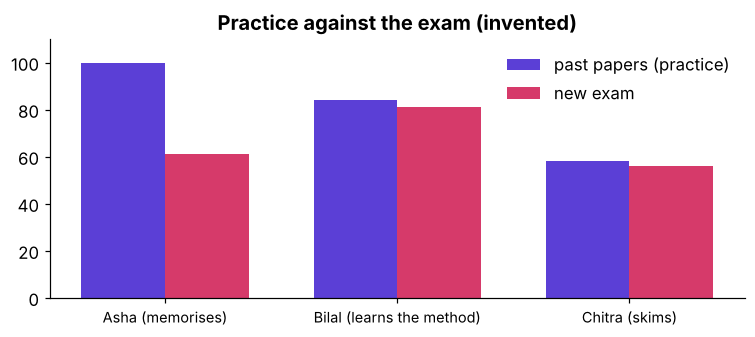

In [2]:
import pandas as pd
# Invented scores, out of 100.
students = pd.DataFrame({"student": ["Asha (memorises)", "Bilal (learns the method)", "Chitra (skims)"],
                         "past_papers": [100, 84, 58], "new_exam": [61, 81, 56]})
students["gap"] = students["past_papers"] - students["new_exam"]
print(students.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.2))
x = range(3)
ax.bar([i - 0.18 for i in x], students["past_papers"], 0.36, color=VIOLET, label="past papers (practice)")
ax.bar([i + 0.18 for i in x], students["new_exam"], 0.36, color=ROSE, label="new exam")
ax.set_xticks(list(x)); ax.set_xticklabels(students["student"], fontsize=9.5)
ax.set_ylim(0, 110); ax.legend(frameon=False); ax.set_title("Practice against the exam (invented)")
plt.tight_layout(); plt.show()

**Two ways to be wrong.** Asha's gap of 39 points is **variance**: she learned the papers, so a new
paper moves her score a lot. Chitra's two low, close scores are **bias**: her approach is too simple to
do well anywhere. Bilal sits close on both, and high. Overfitting is Asha; underfitting is Chitra.

## A tree that never stops asking

Ten invented Kalpa customers. The pattern is "opened three or more nudges last year, then bought",
with three customers who break it. A tree with no depth limit keeps splitting until every leaf is pure.

In [3]:
# Ten Kalpa customers and four new ones, invented for this chapter.
import pandas as pd
old = pd.DataFrame({"customer": list("ABCDEFGHIJ"),
                    "age":    [24, 29, 33, 38, 42, 46, 51, 55, 60, 64],
                    "nudges_opened_last_year": [1, 4, 2, 5, 1, 6, 3, 2, 5, 1],
                    "bought": [0, 1, 0, 1, 1, 0, 1, 0, 1, 0]})
new = pd.DataFrame({"customer": ["K", "L", "M", "N"], "age": [27, 44, 49, 58],
                    "nudges_opened_last_year": [5, 2, 4, 1], "bought": [1, 0, 1, 0]})
COLS = ["age", "nudges_opened_last_year"]
print(old.to_string(index=False))

customer  age  nudges_opened_last_year  bought
       A   24                        1       0
       B   29                        4       1
       C   33                        2       0
       D   38                        5       1
       E   42                        1       1
       F   46                        6       0
       G   51                        3       1
       H   55                        2       0
       I   60                        5       1
       J   64                        1       0


No limit      leaves 5  practice 100%  new customers 75%
One question  leaves 2  practice 80%  new customers 100%


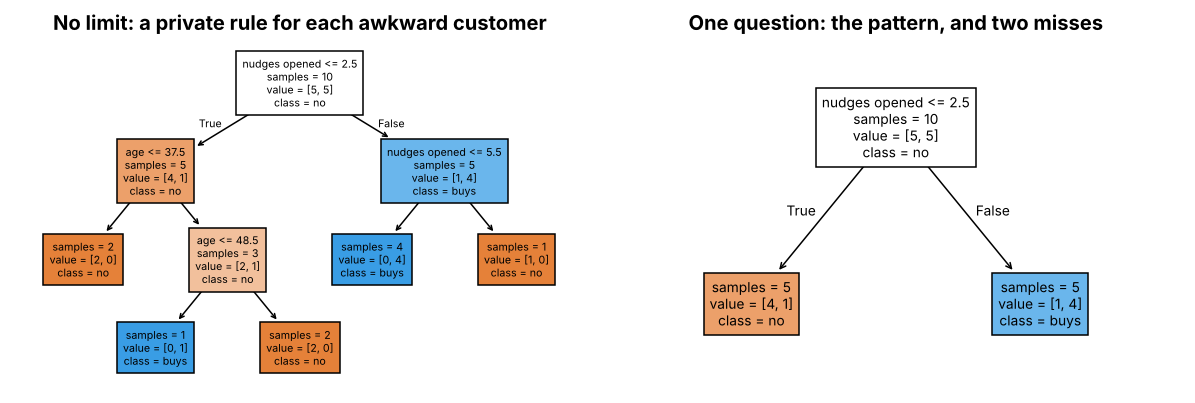

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
memoriser = DecisionTreeClassifier(random_state=0).fit(old[COLS], old["bought"])
stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(old[COLS], old["bought"])
for name, m in [("No limit", memoriser), ("One question", stump)]:
    print(f"{name:13s} leaves {m.get_n_leaves()}  practice {m.score(old[COLS], old['bought']):.0%}"
          f"  new customers {m.score(new[COLS], new['bought']):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_tree(memoriser, feature_names=["age", "nudges opened"], class_names=["no", "buys"],
          filled=True, impurity=False, fontsize=7, ax=axes[0])
axes[0].set_title("No limit: a private rule for each awkward customer")
plot_tree(stump, feature_names=["age", "nudges opened"], class_names=["no", "buys"],
          filled=True, impurity=False, fontsize=9, ax=axes[1])
axes[1].set_title("One question: the pattern, and two misses")
plt.tight_layout(); plt.show()

In [5]:
check("the unlimited tree is perfect on the ten customers it learned from",
      memoriser.score(old[COLS], old["bought"]) == 1.0)
check("the one-question tree does better on the four new customers",
      stump.score(new[COLS], new["bought"]) > memoriser.score(new[COLS], new["bought"]))

PASS  the unlimited tree is perfect on the ten customers it learned from
PASS  the one-question tree does better on the four new customers


## Learning curves from tiny numbers

Give each student one more past paper at a time and score them twice: on the papers they studied and on
a fresh one. Two curves per student, invented.

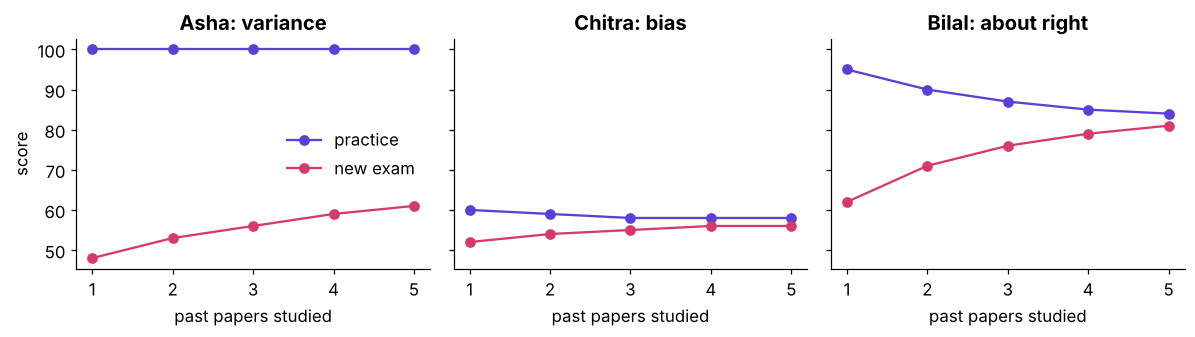

In [6]:
papers = [1, 2, 3, 4, 5]
curves = {"Asha: variance": ([100, 100, 100, 100, 100], [48, 53, 56, 59, 61]),
          "Chitra: bias": ([60, 59, 58, 58, 58], [52, 54, 55, 56, 56]),
          "Bilal: about right": ([95, 90, 87, 85, 84], [62, 71, 76, 79, 81])}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, (name, (practice, exam)) in zip(axes, curves.items()):
    ax.plot(papers, practice, "o-", color=VIOLET, label="practice")
    ax.plot(papers, exam, "o-", color=ROSE, label="new exam")
    ax.set_title(name); ax.set_xlabel("past papers studied"); ax.set_xticks(papers)
axes[0].set_ylabel("score"); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

In [7]:
gap = {k: v[0][-1] - v[1][-1] for k, v in curves.items()}
print("final gap between the two curves:", gap)
check("variance shows as the widest gap", max(gap, key=gap.get) == "Asha: variance")
check("bias shows as two low curves close together", gap["Chitra: bias"] < 5 and curves["Chitra: bias"][1][-1] < 60)

final gap between the two curves: {'Asha: variance': 39, 'Chitra: bias': 2, 'Bilal: about right': 3}
PASS  variance shows as the widest gap
PASS  bias shows as two low curves close together


## Carry this

| What you see | Its name | What helps | When that help fails |
|---|---|---|---|
| Practice high, exam low, a wide gap | variance (overfitting) | a brake (chapter 2), more rows | when the extra rows bring the same noise the model memorises |
| Both low, close together | bias (underfitting) | more capacity, better columns | when the columns carry no signal at all |
| Both high, close together | about right | ship it to the next check | never on one split alone (chapter 3) |

The formal version, the bias-variance decomposition, belongs to the tentative IITGN faculty session.
The curves are what you read at work. Case 1 runs this on 24,712 real customers.